# 06 | Why did postoperative FC depend so strongly on refitting five PCs?

**Learning goals:** diagnose a nuisance-model discontinuity, distinguish spatial resampling from field correction, and compare anatomical component regression without selecting a model from the cognitive outcome.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## A controlled question
All PC-count and image-by-mask diagnostics use **the same corrected cortical ROI signals**, 24 motion terms, trend/<0.01-Hz DCT, FD≤0.5-mm censoring, 100 nodes and corrected SC. Only nuisance signals change. The two complete BOLD pipelines retain their own ROI signals for the separate old/new package comparison.

The historical five PCs used all 180 frames, voxel centering/scaling, and an eroded noncortical mask; this mask was not tissue segmentation. The reconstructed PC subspace matches the saved historical PCs. Signs and orthogonal basis rotations do not affect the regression projection. A PC sign flip cannot explain the FC change.

,PC_source,mean_fc_r,sc_fc_spearman,cortical_mean_partial_R2,residual_df
47,uncorrected,0.267861,0.158710,0.22512,111
68,corrected,0.133487,0.187481,0.71261,111


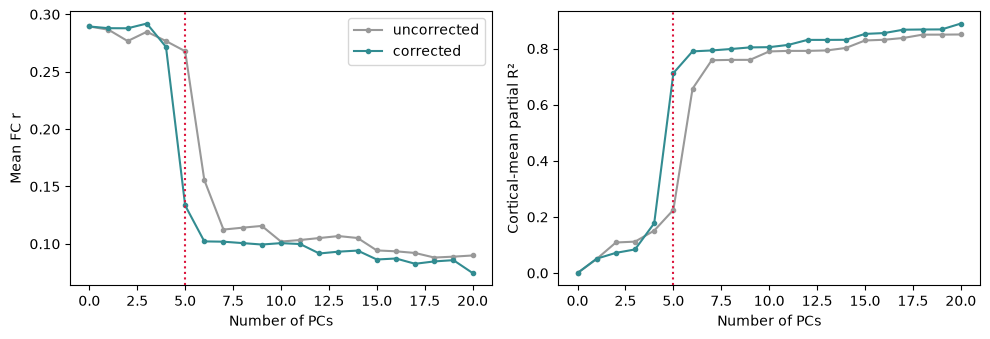

interactive(children=(Dropdown(description='session', index=1, options=('preop', 'postop'), value='postop'), I…

<function __main__.cutoff(session='postop', components=5)>

In [2]:
display(pd.DataFrame(json.loads((RESULTS/"nuisance_investigation/summary.json").read_text())["sessions"]))
display(Image(filename=str(RESULTS/"figures/nuisance_pc_mechanism.png")))
from pat16.nuisance_views import show_cutoff,show_masks,show_model
def cutoff(session="postop",components=5):
    fig=show_cutoff(session,components);plt.show();plt.close(fig)
widgets.interact(cutoff,session=widgets.Dropdown(options=SESSIONS,value="postop"),components=widgets.IntSlider(min=0,max=20,value=5))

### What the cutoff reveals
After identical base motion/DCT regression, the old postoperative five PCs remove 22.5% of the **unweighted cortical ROI mean's residual variance**; the refitted five remove 71.3%. Old PC6 and new PC5 have strong cortical-mean associations, but their partial correlation is only 0.331: this is **not a simple one-to-one PC swap**. With six old PCs, postoperative mean FC drops from 0.268 to 0.156; with ten PCs the old/refitted means are both near 0.10. This diagnoses the cutoff; it does not establish the optimal component count or neural ground truth.

Partial R² measures in-sample variance removed beyond the base regressors. Shared neural activity and non-neural fluctuations can both contribute. It is not the fraction of noise removed.

In [3]:
factorial=pd.read_csv(RESULTS/"nuisance_mask_data_factorial.csv")
display(factorial.pivot(index=["session","image_for_PCA"],columns="mask_for_PCA",values="mean_fc_r"))
display(pd.read_csv(RESULTS/"nuisance_sampling_audit.csv"))

mask_for_PCA              corrected  intersection  old_field_valid  \
session image_for_PCA                                                
postop  corrected          0.133487      0.144115         0.174757   
        cubic_zero_field   0.143176      0.149918         0.178854   
        uncorrected        0.253958      0.247966         0.252826   
preop   corrected          0.359665      0.369822         0.361276   
        cubic_zero_field   0.353262      0.363694         0.358934   
        uncorrected        0.354327      0.364017         0.362943   

mask_for_PCA              uncorrected  
session image_for_PCA                  
postop  corrected            0.224991  
        cubic_zero_field     0.225676  
        uncorrected          0.267861  
preop   corrected            0.361276  
        cubic_zero_field     0.358934  
        uncorrected          0.362943

,session,tested_frames,max_linear_resampling_relative_RMSE,interpretation
0,preop,"4,40,90,130,179",1.335602e-08,Composed order-1 sampling versus historical Si...
1,postop,"4,40,90,130,179",1.220211e-08,Composed order-1 sampling versus historical Si...


### Interpolation, masks and susceptibility
The cubic zero-field control resamples raw BOLD with the **same saved motion and composed cubic sampler**, but zero PE shift and unit Jacobian. It is a diagnostic PCA image; it does not refit ROI registration. The linear sampler is checked against historical SimpleITK data inside the nuisance mask. With the new postoperative mask, mean FC is 0.254 using old linear data, 0.143 using cubic zero-field data and 0.133 using corrected data. Interpolation therefore accounts for much of this diagnostic difference; the remaining difference includes the field and its intensity modulation. No causal percentage is assigned to interacting stages.

The postoperative old/new mask Dice is 0.877 (11,054 versus 9,335 voxels); 684 old voxels fail the corrected field-support check. `old_field_valid` removes these; `intersection` fixes common grid membership. Mixed image/mask combinations are numerical controls, not anatomically preferred complete pipelines. Physical tissue correspondence changes after unwarping.

## Anatomical WM/CSF masks: inspect before interpreting
FSL FAST segments each session's native T1 into CSF/GM/WM partial-volume estimates with bias correction. The existing T1 brain mask excludes the lesion footprint plus 5 mm before fitting; the post-op footprint is not a cavity segmentation. Tissue fractions ≥0.95 are eroded by 1 mm in T1 space and restricted to >2 mm inside the brain. Native core membership (nearest neighbour) **and** interpolated PVE≥0.95 must pass in BOLD space, together with valid support and lesion exclusion. CSF includes ventricular and sulcal tissue. Masks are automatically estimated and need expert review.

Orange = WM; cyan = CSF; magenta = historical noncortical mask. A high PVE-derived purity is internal model consistency, not independent segmentation accuracy.

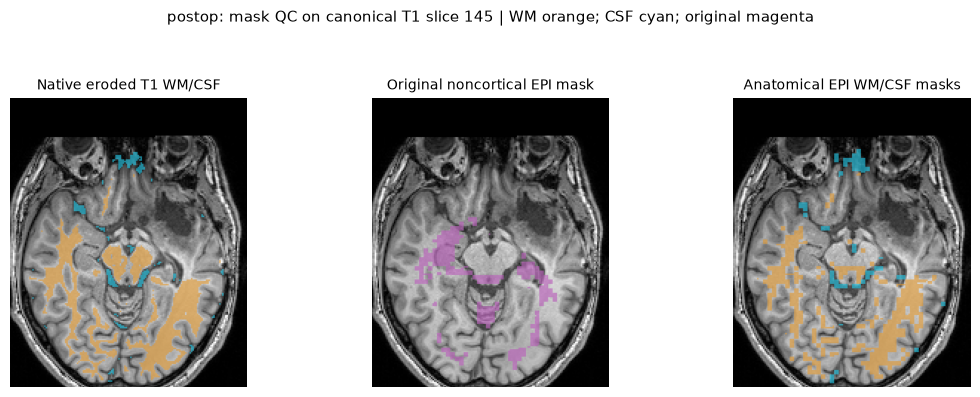

interactive(children=(Dropdown(description='session', index=1, options=('preop', 'postop'), value='postop'), I…

<function __main__.masks(session='postop', z=145)>

In [4]:
display(pd.read_csv(RESULTS/"nuisance_mask_composition.csv").query("BOLD_processing=='corrected'"))
def masks(session="postop",z=145):
    fig=show_masks(session,z);plt.show();plt.close(fig)
widgets.interact(masks,session=widgets.Dropdown(options=SESSIONS,value="postop"),z=widgets.IntSlider(min=40,max=220,value=145))

## Primary recommendation and five alternative nuisance models
**Primary: retained-frame anatomical five-PC regression.** Anatomical specificity and exclusion of censored samples from PCA motivate this choice; five components preserve the earlier budget (107/111 residual df). Tissue means are parsimonious but cannot represent multiple spatial noise directions; separate WM5+CSF5 uses ten PCs and remains a useful sensitivity. Combined PCA has more WM than CSF voxels, so tissue contributions are not balanced. No model is selected by cognitive agreement, lowest FC or highest coupling. This is a post hoc recommendation, not preregistration or proof of physiological superiority. General CompCor/aCompCor evidence supports tissue-based components, while cohort benchmarks show tradeoffs (Behzadi 2007; Muschelli 2014; Ciric 2017; see report).

All use joint final regression with the same motion/DCT terms and no explicit GSR. `anatomical5_raw` changes only the mask relative to historical all-frame PCA. `anatomical5` first projects constant/linear/<0.01-Hz DCT, scales voxels and fits PCA **on retained original indices**, then projects all frames with the fitted spatial weights. No temporal concatenation or interpolation across censor gaps occurs. `wm5_csf5` uses 5 PCs per tissue (10 total); `wm_csf_means` uses two tissue means. This is custom anatomical component regression inspired by CompCor, not a claim to reproduce fMRIPrep.

The anatomy-based five-PC model gives mean FC 0.087 pre-op and 0.046 post-op, versus 0.360/0.133 historically; coupling is evaluated on the primary 823-edge common consensus in the table below; original seed-160 coupling remains available in the archived CSV. It removes about 91%/90% of cortical-mean residual variance. This can remove both physiological artifacts and neural covariance. There are no physiological recordings or independently validated tissue labels to rank biological accuracy.

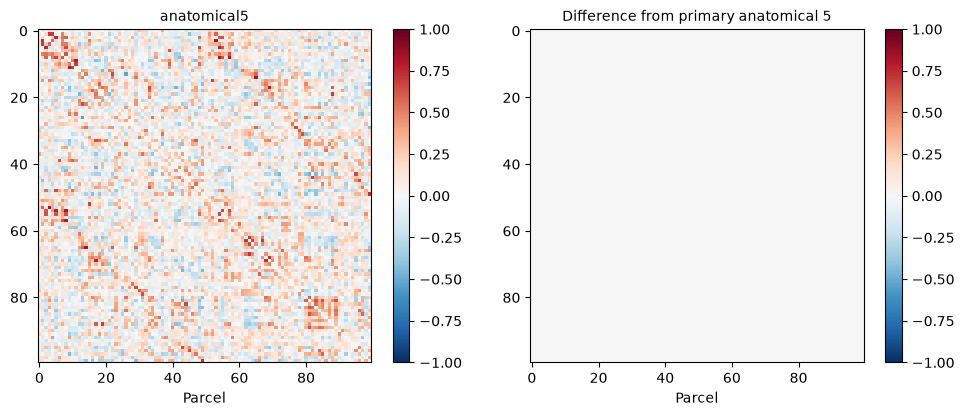

interactive(children=(Dropdown(description='session', index=1, options=('preop', 'postop'), value='postop'), D…

<function __main__.matrix(session='postop', model='anatomical5')>

In [5]:
models=pd.read_csv(RESULTS/"primary_sc/denoising_comparison.csv")
display(models.query("BOLD_processing=='corrected'")[["session","model","nuisance_regressors","retained_frames","residual_df","mean_fc_r","sc_fc_spearman","cortical_mean_partial_R2","mean_ROI_partial_R2"]])
display(Image(filename=str(RESULTS/"figures/primary_sc_denoising.png")))
def matrix(session="postop",model="anatomical5"):
    fig=show_model(session,model);plt.show();plt.close(fig)
widgets.interact(matrix,session=widgets.Dropdown(options=SESSIONS,value="postop"),model=widgets.Dropdown(options=models.model.unique().tolist(),value="anatomical5"))

In [6]:
display(models.query("model in ['original5','anatomical5_raw','anatomical5']")[["session","BOLD_processing","model","mean_fc_r","sc_fc_spearman"]])
anatomical_sensitivity=pd.read_csv(RESULTS/"nuisance_anatomical_sensitivity.csv")
def sensitivity(session="postop",threshold=.95,components=5):
    display(anatomical_sensitivity[(anatomical_sensitivity.session==session)&(anatomical_sensitivity.PVE_threshold==threshold)&(anatomical_sensitivity.components==components)])
widgets.interact(sensitivity,session=widgets.Dropdown(options=SESSIONS,value="postop"),threshold=widgets.SelectionSlider(options=[.90,.95,.99],value=.95),components=widgets.SelectionSlider(options=[2,5,10],value=5))
display(pd.read_csv(RESULTS/"nuisance_network_summary.csv").query("BOLD_processing=='corrected' and model in ['original5','anatomical5']"))

,session,BOLD_processing,PVE_threshold,components,FD_threshold,WM_voxels,CSF_voxels,mean_fc_r,sc_fc_spearman,residual_df
24,postop,uncorrected,0.95,5,0.5,9934,1830,0.047990,0.196265,111
29,postop,uncorrected,0.95,5,0.3,9934,1830,0.048793,0.169818,57
34,postop,corrected,0.95,5,0.5,9586,1738,0.045607,0.189426,111
39,postop,corrected,0.95,5,0.3,9586,1738,0.041219,0.167510,57


interactive(children=(Dropdown(description='session', index=1, options=('preop', 'postop'), value='postop'), S…

,session,BOLD_processing,model,network,within_fc_fisher_z
49,preop,corrected,original5,Vis,0.661571
50,preop,corrected,original5,SomMot,0.606890
51,preop,corrected,original5,DorsAttn,0.633802
52,preop,corrected,original5,SalVentAttn,0.452136
53,preop,corrected,original5,Limbic,0.436970
54,preop,corrected,original5,Cont,0.493627
55,preop,corrected,original5,Default,0.402333
63,preop,corrected,anatomical5,Vis,0.281717
64,preop,corrected,anatomical5,SomMot,0.265161
65,preop,corrected,anatomical5,DorsAttn,0.254676


## Audit the recommended five-PC cutoff
A 0–20 anatomical-PC sweep uses the same saved tissue PCA, fixed masks and retained frames. Adjacent postoperative 4/5/6-PC means are 0.0477/0.0456/0.0449, much closer than the historical cutoff jump; preoperative means are 0.0864/0.0872/0.0721. This check supports a pragmatic five-component budget, not an optimized count or neural validation. Wider count dependence remains visible.

In [7]:
primary_counts=pd.read_csv(RESULTS/"primary_sc/pc_sensitivity.csv")
display(Image(filename=str(RESULTS/"figures/primary_sc_pc_count.png")))
def adjacent_count(components=5):
    display(primary_counts[(primary_counts.BOLD_processing=="corrected")&(primary_counts.components==components)])
widgets.interact(adjacent_count,components=widgets.IntSlider(min=0,max=20,value=5))

,session,BOLD_processing,components,PVE_threshold,FD_threshold,mean_fc_r,sc_fc_spearman,residual_df,role,SC_reference
26,preop,corrected,5,0.95,0.5,0.087228,0.188216,107,primary,repeat80-mean-seed-rate-common-coupling-v1
68,postop,corrected,5,0.95,0.5,0.045607,0.146488,111,primary,repeat80-mean-seed-rate-common-coupling-v1


interactive(children=(IntSlider(value=5, description='components', max=20), Output()), _dom_classes=('widget-i…

<function __main__.adjacent_count(components=5)>

## What survives, and what remains uncertain?
The anatomy-based five-PC old/new BOLD gap is small postoperatively (0.048 versus 0.046), compared with 0.272 versus 0.133 historically. At 0.90–0.99 tissue thresholds, corrected means range 0.084–0.089 pre-op and 0.045–0.048 post-op. Component count still matters. Stricter FD≤0.3-mm censoring refits anatomical PCs on its retained frames and leaves only 29/57 residual degrees of freedom; unequal, shorter runs limit the comparison. Under the current common-consensus SC rule, coupling is 0.188→0.146 at FD0.5 and 0.161→0.127 under strict FD. The earlier 0.210→0.189 versus 0.156→0.168 reversal used original own-support SC and remains a historical sensitivity. Notebook 07 separates frame restriction, coefficient/PCA refitting, matched duration/FD/run halves and SC-support dependence; its matched refits also leave the direction unresolved.

The historical primary FC/report/tables are frozen under `results/before_primary_anatomical5`; FC still uses `anatomical5`; primary SC now uses repeated-seed consensus as specified above. Original SC arrays remain immutable. The previous main delivery is archived under `results/before_primary_sc`. All six models, masks, regressors and diagnostics remain under `results/nuisance_investigation`. Regenerate using `uv run python scripts/investigate_nuisance.py`; FSL FAST is needed only if tissue segmentation is absent or deliberately forced. Report Appendix A explains the assessments used in notebook 04. The primary recipe is fixed across sessions and is not chosen for agreement with cognition; no two-time-point correlation is interpreted as evidence.

**Exercises:** compare five with six PCs; compare raw anatomical with retained-frame anatomical PCA; inspect tissue masks near the ventricles, cortex and lesion; ask which claims depend on mean FC versus SC–FC coupling. Which independent physiological or retest data would help distinguish artifact removal from neural signal loss?